# LIBRERIAS

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

from jedi.inference.value import dynamic_arrays
from pandas import read_csv

# Librería para gráficos interactivos
import plotly.express as px
import plotly.graph_objects as go

# LECTURA DEL DATASET

In [2]:
df = pd.read_csv(r"C:\Users\marie\Downloads\music_streaming_habits_2026.csv")
df.head(5)

,listener_id,age,country,platform,subscription,top_genre,top_artist,daily_listening_minutes,songs_per_day,playlists_count,skip_rate_pct,discover_weekly_user,top_mood,uses_offline_mode,podcasts_too
0,1,24,Australia,Apple Music,Free,R&B,Kendrick Lamar,191,54,9,39.3,False,Sleep,False,True
1,2,21,Germany,Spotify,Free,Classical,Drake,249,68,10,18.3,True,Workout,True,True
2,3,32,Japan,Amazon Music,Free,Hip-Hop,Olivia Rodrigo,49,11,11,22.7,True,Sad,False,True
3,4,39,Japan,Apple Music,Free,Pop,Burna Boy,96,22,8,29.4,True,Sad,True,False
4,5,23,India,Spotify,Family,Country,Olivia Rodrigo,100,24,13,37.7,True,Workout,True,True


In [4]:
df.shape

(4000, 15)

## Se eliminaran columnas tales como: 	listener_id, skip_rate_pct, discover_weekly_user, uses_offline_mode
## Ya que no son necesarias para este analisis
## se renombran las columnas

In [5]:
df = df.drop(columns=[
    "listener_id",
    "skip_rate_pct",
    "discover_weekly_user" ,
    "uses_offline_mode"])

df.head(5)

,age,country,platform,subscription,top_genre,top_artist,daily_listening_minutes,songs_per_day,playlists_count,top_mood,podcasts_too
0,24,Australia,Apple Music,Free,R&B,Kendrick Lamar,191,54,9,Sleep,True
1,21,Germany,Spotify,Free,Classical,Drake,249,68,10,Workout,True
2,32,Japan,Amazon Music,Free,Hip-Hop,Olivia Rodrigo,49,11,11,Sad,True
3,39,Japan,Apple Music,Free,Pop,Burna Boy,96,22,8,Sad,False
4,23,India,Spotify,Family,Country,Olivia Rodrigo,100,24,13,Workout,True


In [6]:
df = df.rename(columns={"age": "edad",
                        "country": "pais",
                        "platform": "plataforma",
                        "subscription": "suscripcion",
                        "top_genre":"genero_favorito",
                        "top_artist": "top_artista",
                        "daily_listening_minutes": "minutosXdia",
                        "songs_per_day": "cancionesXdia",
                        "playlists_count": "playlist",
                        "top_mood": "estado_animo",
                        "podcasts_too":"podcast",})

df.head(5)

,edad,pais,plataforma,suscripcion,genero_favorito,top_artista,minutosXdia,cancionesXdia,playlist,estado_animo,podcast
0,24,Australia,Apple Music,Free,R&B,Kendrick Lamar,191,54,9,Sleep,True
1,21,Germany,Spotify,Free,Classical,Drake,249,68,10,Workout,True
2,32,Japan,Amazon Music,Free,Hip-Hop,Olivia Rodrigo,49,11,11,Sad,True
3,39,Japan,Apple Music,Free,Pop,Burna Boy,96,22,8,Sad,False
4,23,India,Spotify,Family,Country,Olivia Rodrigo,100,24,13,Workout,True


In [7]:
df.isna().sum()

edad               0
pais               0
plataforma         0
suscripcion        0
genero_favorito    0
top_artista        0
minutosXdia        0
cancionesXdia      0
playlist           0
estado_animo       0
podcast            0
dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   edad             4000 non-null   int64 
 1   pais             4000 non-null   object
 2   plataforma       4000 non-null   object
 3   suscripcion      4000 non-null   object
 4   genero_favorito  4000 non-null   object
 5   top_artista      4000 non-null   object
 6   minutosXdia      4000 non-null   int64 
 7   cancionesXdia    4000 non-null   int64 
 8   playlist         4000 non-null   int64 
 9   estado_animo     4000 non-null   object
 10  podcast          4000 non-null   bool  
dtypes: bool(1), int64(4), object(6)
memory usage: 316.5+ KB


In [9]:
df["podcast"] = df["podcast"].astype("Int64")
df.head(5)

,edad,pais,plataforma,suscripcion,genero_favorito,top_artista,minutosXdia,cancionesXdia,playlist,estado_animo,podcast
0,24,Australia,Apple Music,Free,R&B,Kendrick Lamar,191,54,9,Sleep,1
1,21,Germany,Spotify,Free,Classical,Drake,249,68,10,Workout,1
2,32,Japan,Amazon Music,Free,Hip-Hop,Olivia Rodrigo,49,11,11,Sad,1
3,39,Japan,Apple Music,Free,Pop,Burna Boy,96,22,8,Sad,0
4,23,India,Spotify,Family,Country,Olivia Rodrigo,100,24,13,Workout,1


In [12]:
df.describe()

,edad,minutosXdia,cancionesXdia,playlist,podcast
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.0
mean,27.849000,138.702750,39.137500,8.994500,0.468
std,8.595881,86.296023,25.046296,3.027914,0.499037
min,13.000000,5.000000,1.000000,1.000000,0.0
25%,22.000000,74.000000,21.000000,7.000000,0.0
50%,28.000000,122.000000,35.000000,9.000000,0.0
75%,34.000000,185.000000,52.250000,11.000000,1.0
max,57.000000,697.000000,198.000000,22.000000,1.0


## Guardar dataset ya limpio

In [13]:
os.makedirs("../DATA/PROCESSED", exist_ok=True)
df.to_csv("../DATA/PROCESSED/music_streaming_habits_limpio.csv", index=False)

PermissionError: [WinError 5] Access is denied: '../DATA'

# GRAFICOS E INTERPRETACIONES

## 1. Distribución de las variables numéricas

En estos gráficos se puede observar cómo se distribuyen las edades, los minutos de escucha, la cantidad de canciones por día y las listas de reproducción. Al pasar el cursor sobre las barras se pueden consultar los valores.

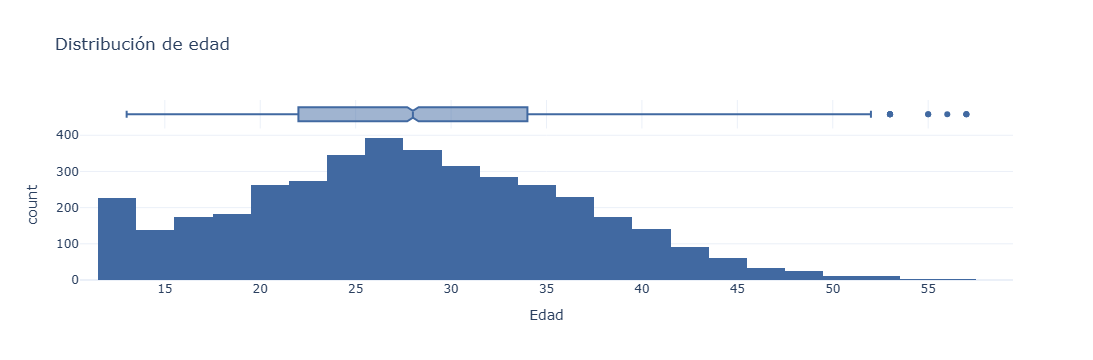

Interpretación: Para edad, el promedio es 27.85 y la mediana es 28.00. Los valores se encuentran entre 13 y 57. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


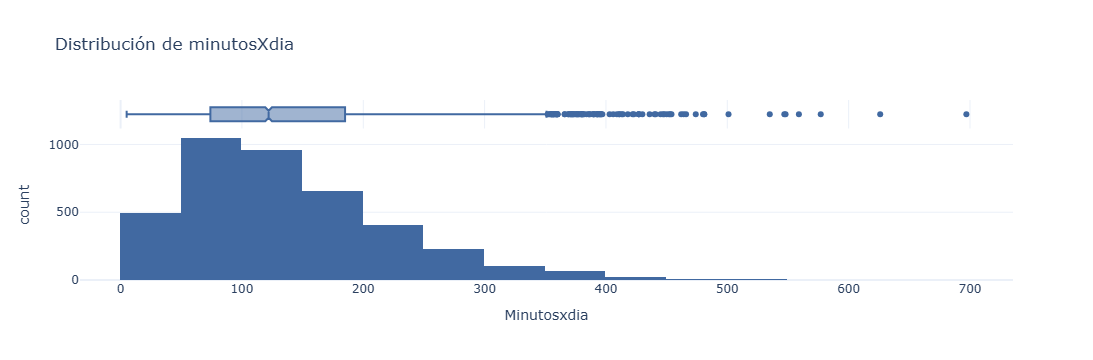

Interpretación: Para minutosXdia, el promedio es 138.70 y la mediana es 122.00. Los valores se encuentran entre 5 y 697. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


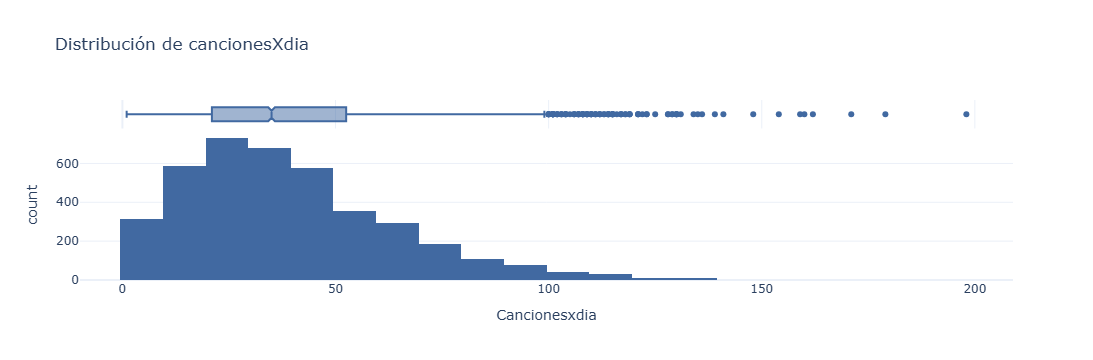

Interpretación: Para cancionesXdia, el promedio es 39.14 y la mediana es 35.00. Los valores se encuentran entre 1 y 198. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


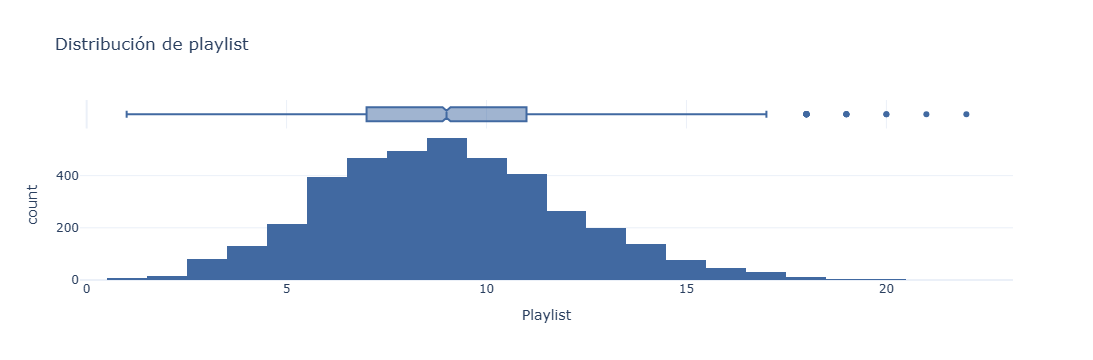

Interpretación: Para playlist, el promedio es 8.99 y la mediana es 9.00. Los valores se encuentran entre 1 y 22. El gráfico permite identificar en qué rangos se concentra la mayoría de los registros y observar posibles valores extremos.


In [14]:
variables_numericas = ["edad", "minutosXdia", "cancionesXdia", "playlist"]

for variable in variables_numericas:
    fig = px.histogram(
        df,
        x=variable,
        nbins=30,
        marginal="box",
        title=f"Distribución de {variable}",
        labels={variable: variable.replace("_", " ").title(), "count": "Cantidad de personas"},
        color_discrete_sequence=["#4169A1"]
    )
    fig.update_layout(template="plotly_white", hovermode="x unified")
    fig.show()

    promedio = df[variable].mean()
    mediana = df[variable].median()
    minimo = df[variable].min()
    maximo = df[variable].max()

    print(
        f"Interpretación: Para {variable}, el promedio es {promedio:.2f} "
        f"y la mediana es {mediana:.2f}. Los valores se encuentran entre "
        f"{minimo} y {maximo}. El gráfico permite identificar en qué rangos "
        f"se concentra la mayoría de los registros y observar posibles valores extremos."
    )

## 2. Comparación de las variables numéricas

El diagrama de caja permite comparar la dispersión de los datos y detectar observaciones que se alejan del comportamiento general.

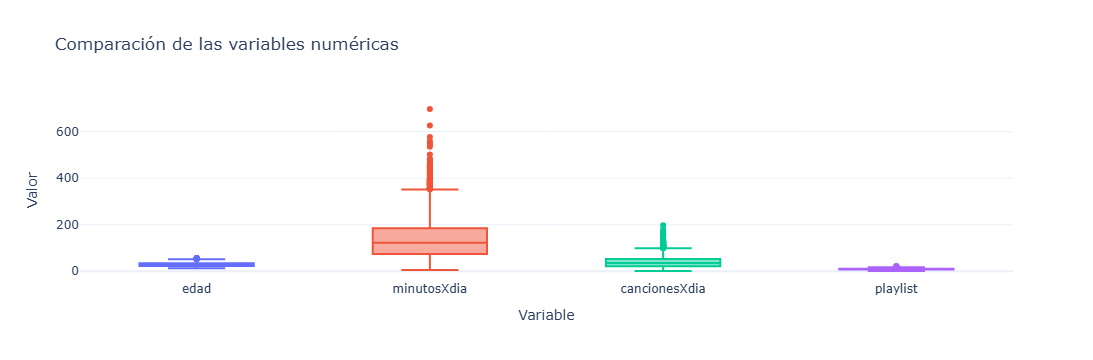

Interpretación: El gráfico permite comparar la variabilidad de las edades, los minutos de escucha, las canciones por día y las listas de reproducción. Los puntos que aparecen fuera de los bigotes representan posibles valores atípicos. Cada variable tiene una escala diferente, por lo que se debe interpretar considerando sus propias unidades.


In [16]:
datos_numericos = df[variables_numericas].melt(
    var_name="Variable",
    value_name="Valor"
)

fig = px.box(
    datos_numericos,
    x="Variable",
    y="Valor",
    color="Variable",
    points="outliers",
    title="Comparación de las variables numéricas"
)
fig.update_layout(template="plotly_white", showlegend=False)
fig.show()

print(
    "Interpretación: El gráfico permite comparar la variabilidad de las edades, "
    "los minutos de escucha, las canciones por día y las listas de reproducción. "
    "Los puntos que aparecen fuera de los bigotes representan posibles valores "
    "atípicos. Cada variable tiene una escala diferente, por lo que se debe "
    "interpretar considerando sus propias unidades."
)

## 3. Frecuencia de las variables categóricas

Los gráficos de barras muestran cuántos registros pertenecen a cada categoría. Se pueden explorar las plataformas, los países, las suscripciones, los géneros, los artistas, los estados de ánimo y el consumo de podcasts.

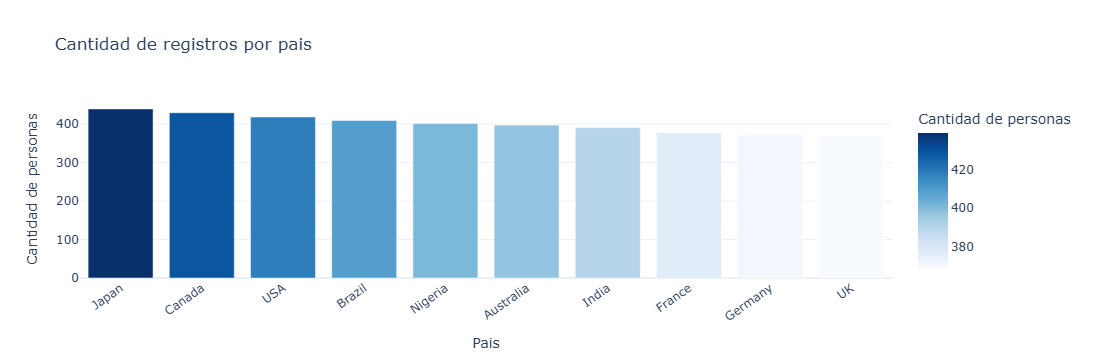

Interpretación: La categoría más frecuente en pais es 'Japan', con 439 registros (11.0% del total). Esto permite reconocer cuál opción se presenta con mayor frecuencia en el conjunto de datos.


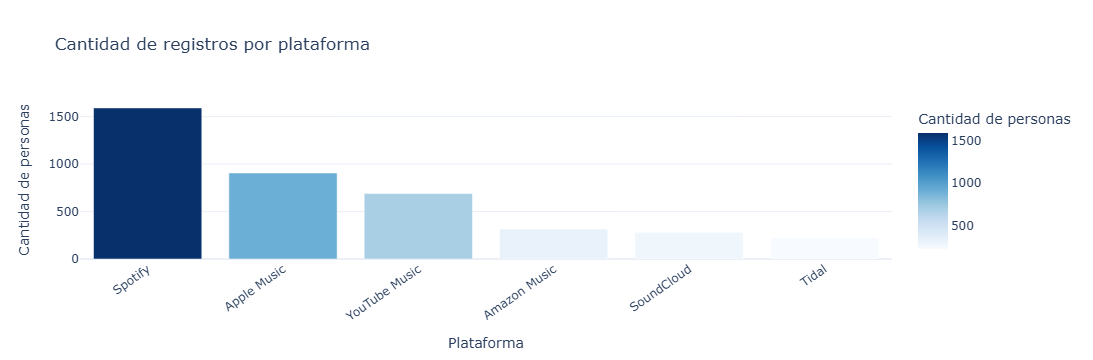

Interpretación: La categoría más frecuente en plataforma es 'Spotify', con 1591 registros (39.8% del total). Esto permite reconocer cuál opción se presenta con mayor frecuencia en el conjunto de datos.


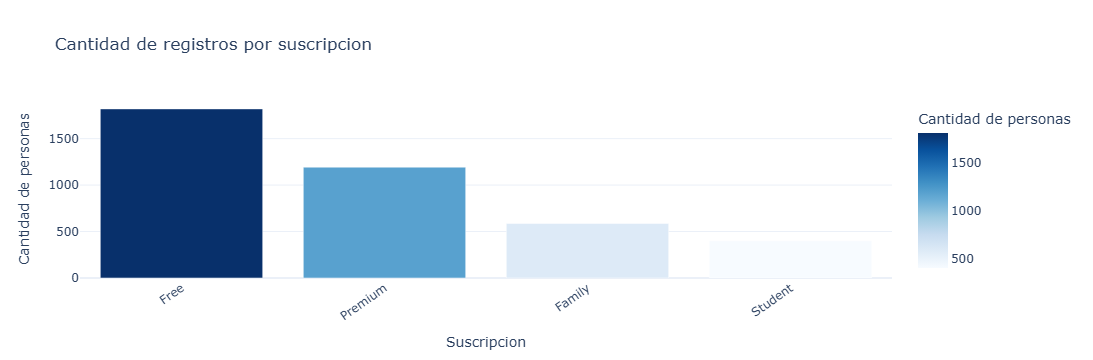

Interpretación: La categoría más frecuente en suscripcion es 'Free', con 1820 registros (45.5% del total). Esto permite reconocer cuál opción se presenta con mayor frecuencia en el conjunto de datos.


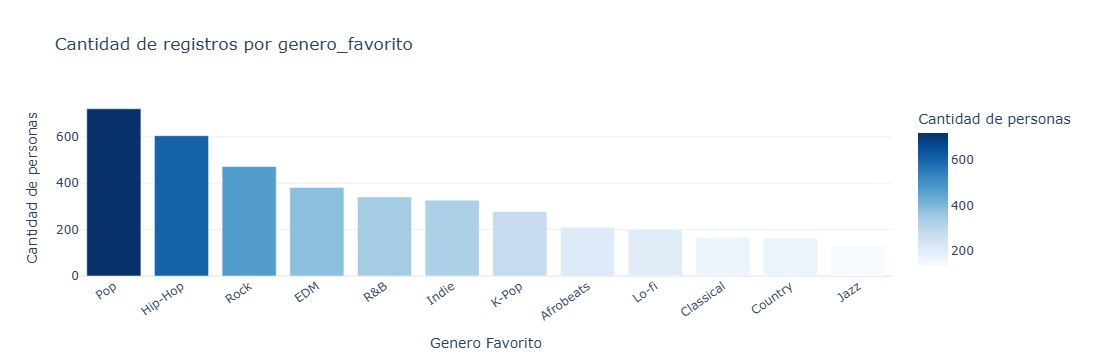

Interpretación: La categoría más frecuente en genero_favorito es 'Pop', con 721 registros (18.0% del total). Esto permite reconocer cuál opción se presenta con mayor frecuencia en el conjunto de datos.


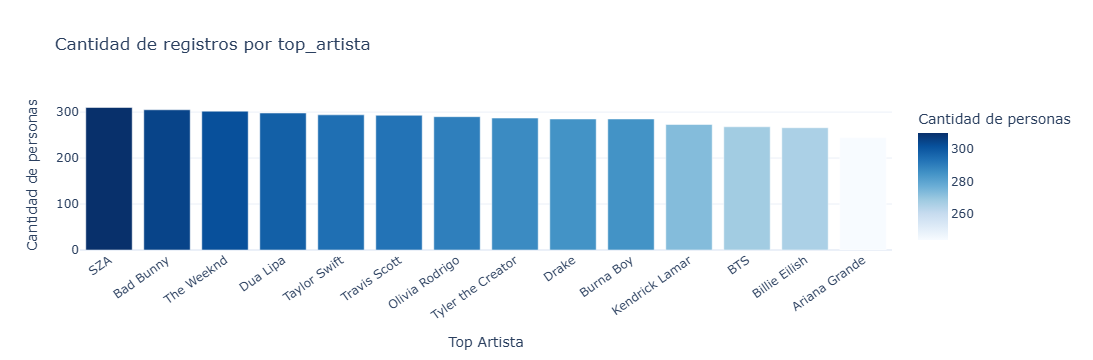

Interpretación: La categoría más frecuente en top_artista es 'SZA', con 310 registros (7.8% del total). Esto permite reconocer cuál opción se presenta con mayor frecuencia en el conjunto de datos.


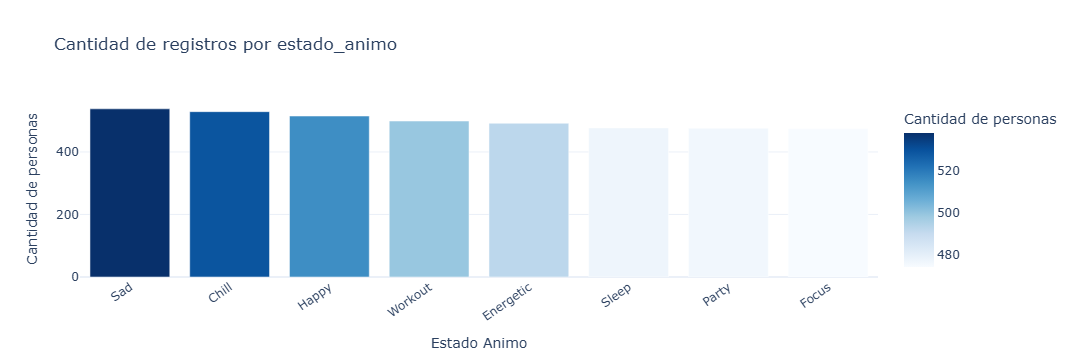

Interpretación: La categoría más frecuente en estado_animo es 'Sad', con 538 registros (13.5% del total). Esto permite reconocer cuál opción se presenta con mayor frecuencia en el conjunto de datos.


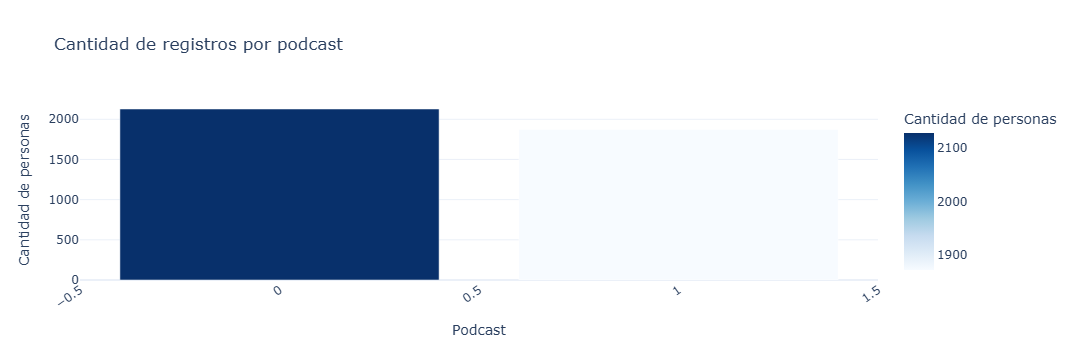

Interpretación: La categoría más frecuente en podcast es '0', con 2128 registros (53.2% del total). Esto permite reconocer cuál opción se presenta con mayor frecuencia en el conjunto de datos.


In [17]:
variables_categoricas = [
    "pais", "plataforma", "suscripcion", "genero_favorito",
    "top_artista", "estado_animo", "podcast"
]

for variable in variables_categoricas:
    frecuencias = df[variable].value_counts().reset_index()
    frecuencias.columns = [variable, "cantidad"]
    frecuencias = frecuencias.sort_values("cantidad", ascending=False)

    fig = px.bar(
        frecuencias,
        x=variable,
        y="cantidad",
        title=f"Cantidad de registros por {variable}",
        labels={variable: variable.replace("_", " ").title(),
                "cantidad": "Cantidad de personas"},
        color="cantidad",
        color_continuous_scale="Blues",
        hover_data={"cantidad": True}
    )
    fig.update_layout(template="plotly_white", xaxis_tickangle=-35)
    fig.show()

    categoria_mayor = frecuencias.iloc[0][variable]
    cantidad_mayor = int(frecuencias.iloc[0]["cantidad"])
    porcentaje = cantidad_mayor / len(df) * 100

    print(
        f"Interpretación: La categoría más frecuente en {variable} es "
        f"'{categoria_mayor}', con {cantidad_mayor} registros "
        f"({porcentaje:.1f}% del total). Esto permite reconocer cuál opción "
        f"se presenta con mayor frecuencia en el conjunto de datos."
    )

## 4. Minutos de escucha según la plataforma

Se compara el tiempo diario de escucha entre las plataformas. El diagrama de caja permite observar la mediana, la dispersión y los posibles valores atípicos de cada grupo.

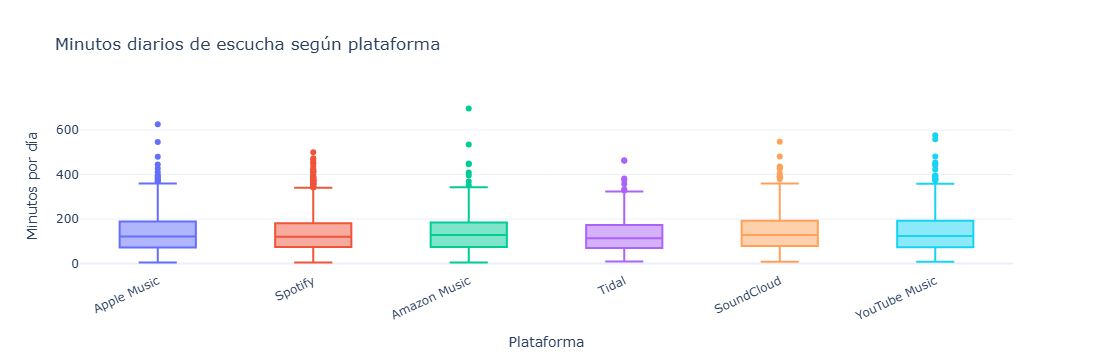

Interpretación: La plataforma con el promedio más alto de minutos diarios es SoundCloud, con 145.9 minutos. La comparación describe los hábitos registrados en cada plataforma, pero no demuestra que la plataforma sea la causa de escuchar más música.


In [18]:
fig = px.box(
    df,
    x="plataforma",
    y="minutosXdia",
    color="plataforma",
    points="outliers",
    title="Minutos diarios de escucha según plataforma",
    labels={"plataforma": "Plataforma", "minutosXdia": "Minutos por día"}
)
fig.update_layout(template="plotly_white", showlegend=False, xaxis_tickangle=-25)
fig.show()

promedios_plataforma = df.groupby("plataforma")["minutosXdia"].mean().sort_values(ascending=False)
print(
    f"Interpretación: La plataforma con el promedio más alto de minutos diarios "
    f"es {promedios_plataforma.index[0]}, con {promedios_plataforma.iloc[0]:.1f} "
    f"minutos. La comparación describe los hábitos registrados en cada plataforma, "
    f"pero no demuestra que la plataforma sea la causa de escuchar más música."
)

## 5. Canciones escuchadas según el estado de ánimo

Este gráfico permite comparar la cantidad de canciones escuchadas por día según el estado de ánimo indicado por cada persona.

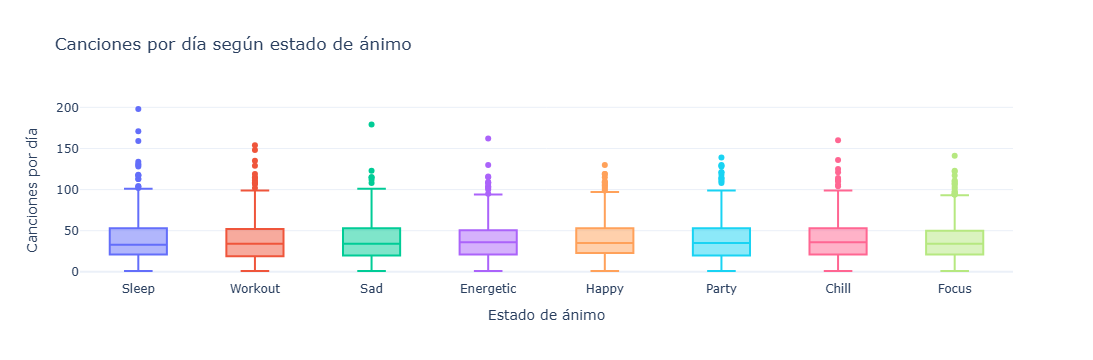

Interpretación: El estado de ánimo con el promedio más alto de canciones escuchadas por día es Sleep, con 40.3 canciones. El gráfico permite observar si existen diferencias entre los grupos.


In [19]:
fig = px.box(
    df,
    x="estado_animo",
    y="cancionesXdia",
    color="estado_animo",
    points="outliers",
    title="Canciones por día según estado de ánimo",
    labels={"estado_animo": "Estado de ánimo", "cancionesXdia": "Canciones por día"}
)
fig.update_layout(template="plotly_white", showlegend=False)
fig.show()

promedios_animo = df.groupby("estado_animo")["cancionesXdia"].mean().sort_values(ascending=False)
print(
    f"Interpretación: El estado de ánimo con el promedio más alto de canciones "
    f"escuchadas por día es {promedios_animo.index[0]}, con "
    f"{promedios_animo.iloc[0]:.1f} canciones. El gráfico permite observar "
    f"si existen diferencias entre los grupos."
)

## 6. Relación entre minutos de escucha y canciones por día

El diagrama de dispersión permite observar si las personas que dedican más minutos a escuchar música también suelen escuchar una mayor cantidad de canciones.

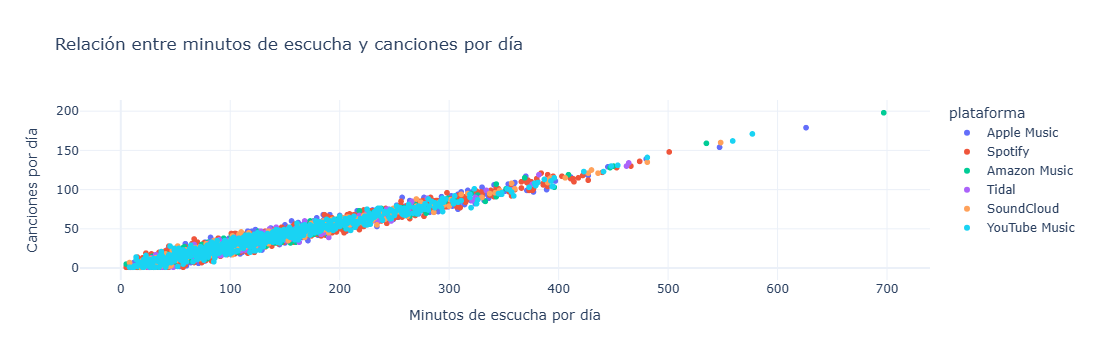

Interpretación: La correlación entre los minutos de escucha y las canciones por día es 0.98, lo que indica una relación positiva marcada. Esto permite observar cómo se relacionan ambas variables, pero no significa que una cause la otra.


In [20]:
fig = px.scatter(
    df,
    x="minutosXdia",
    y="cancionesXdia",
    color="plataforma",
    hover_data=["edad", "genero_favorito", "estado_animo"],
    title="Relación entre minutos de escucha y canciones por día",
    labels={"minutosXdia": "Minutos de escucha por día",
            "cancionesXdia": "Canciones por día"}
)
fig.update_layout(template="plotly_white")
fig.show()

correlacion = df["minutosXdia"].corr(df["cancionesXdia"])

if correlacion > 0.5:
    nivel = "una relación positiva marcada"
elif correlacion > 0.2:
    nivel = "una relación positiva moderada"
elif correlacion >= -0.2:
    nivel = "una relación lineal débil o prácticamente inexistente"
elif correlacion >= -0.5:
    nivel = "una relación negativa moderada"
else:
    nivel = "una relación negativa marcada"

print(
    f"Interpretación: La correlación entre los minutos de escucha y las canciones "
    f"por día es {correlacion:.2f}, lo que indica {nivel}. Esto permite observar "
    f"cómo se relacionan ambas variables, pero no significa que una cause la otra."
)

## 7. Matriz de correlación

La matriz resume la relación lineal entre las variables numéricas. Los valores cercanos a 1 indican una relación positiva, los cercanos a -1 una relación negativa y los cercanos a 0 una relación lineal débil.

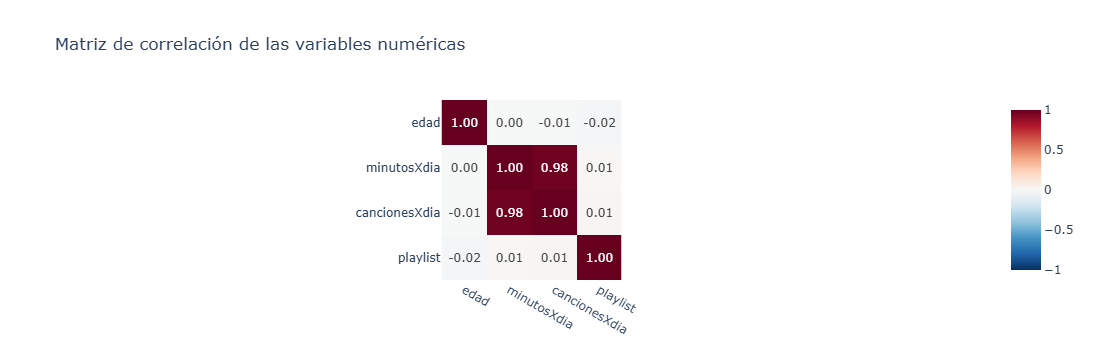

Interpretación: La matriz permite identificar qué variables presentan relaciones lineales más fuertes. La diagonal muestra valores de 1 porque cada variable tiene una correlación perfecta consigo misma. Las correlaciones no representan necesariamente relaciones de causa y efecto.


In [21]:
matriz_correlacion = df[variables_numericas].corr()

fig = px.imshow(
    matriz_correlacion,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Matriz de correlación de las variables numéricas"
)
fig.update_layout(template="plotly_white")
fig.show()

print(
    "Interpretación: La matriz permite identificar qué variables presentan "
    "relaciones lineales más fuertes. La diagonal muestra valores de 1 porque "
    "cada variable tiene una correlación perfecta consigo misma. Las correlaciones "
    "no representan necesariamente relaciones de causa y efecto."
)